In [ ]:

print("Welcome to BankFlow!")
print("We are investigating bank branch efficiency.")
print("All our initial data will be simulated.")

Welcome to BankFlow!
We are investigating bank branch efficiency.
All our initial data will be simulated.


In [ ]:

# Our fictional bank branch

bank_name = "BankFlow Branch"

total_counters = 3

counter_1 = "Cash Services"
counter_2 = "Money Transfers"
counter_3 = "Account Services"

print("Bank name:", bank_name)
print("Total counters:", total_counters)
print("Counter 1:", counter_1)
print("Counter 2:", counter_2)
print("Counter 3:", counter_3)


Bank name: BankFlow Branch
Total counters: 3
Counter 1: Cash Services
Counter 2: Money Transfers
Counter 3: Account Services


In [ ]:

# Our first five fictional bank customers

customers = [
    {"customer_id": 1, "arrival_time": 0, "service": "Money Transfer"},
    {"customer_id": 2, "arrival_time": 2, "service": "Cash Withdrawal"},
    {"customer_id": 3, "arrival_time": 3, "service": "Account Services"},
    {"customer_id": 4, "arrival_time": 5, "service": "Money Transfer"},
    {"customer_id": 5, "arrival_time": 6, "service": "Cash Withdrawal"}
]

print(customers)


[{'customer_id': 1, 'arrival_time': 0, 'service': 'Money Transfer'}, {'customer_id': 2, 'arrival_time': 2, 'service': 'Cash Withdrawal'}, {'customer_id': 3, 'arrival_time': 3, 'service': 'Account Services'}, {'customer_id': 4, 'arrival_time': 5, 'service': 'Money Transfer'}, {'customer_id': 5, 'arrival_time': 6, 'service': 'Cash Withdrawal'}]


In [ ]:

# BankFlow dataset with service durations

customers = [
    {"customer_id": 1, "arrival_time": 0, "service": "Money Transfer", "service_duration": 4},
    {"customer_id": 2, "arrival_time": 2, "service": "Cash Withdrawal", "service_duration": 3},
    {"customer_id": 3, "arrival_time": 3, "service": "Account Services", "service_duration": 6},
    {"customer_id": 4, "arrival_time": 5, "service": "Money Transfer", "service_duration": 5},
    {"customer_id": 5, "arrival_time": 6, "service": "Cash Withdrawal", "service_duration": 2}
]

print(customers)


[{'customer_id': 1, 'arrival_time': 0, 'service': 'Money Transfer', 'service_duration': 4}, {'customer_id': 2, 'arrival_time': 2, 'service': 'Cash Withdrawal', 'service_duration': 3}, {'customer_id': 3, 'arrival_time': 3, 'service': 'Account Services', 'service_duration': 6}, {'customer_id': 4, 'arrival_time': 5, 'service': 'Money Transfer', 'service_duration': 5}, {'customer_id': 5, 'arrival_time': 6, 'service': 'Cash Withdrawal', 'service_duration': 2}]


In [ ]:

# Get the first two customer records

customer_1 = customers[0]
customer_2 = customers[1]

# When does customer 1 finish?

customer_1_finish = (
    customer_1["arrival_time"]
    + customer_1["service_duration"]
)

# When can customer 2 start?

customer_2_start = max(
    customer_2["arrival_time"],
    customer_1_finish
)

# Calculate customer 2's waiting time

customer_2_wait = (
    customer_2_start
    - customer_2["arrival_time"]
)

print("Customer 1 finishes at:", customer_1_finish, "minutes")
print("Customer 2 starts at:", customer_2_start, "minutes")
print("Customer 2 waits:", customer_2_wait, "minutes")


Customer 1 finishes at: 4 minutes
Customer 2 starts at: 4 minutes
Customer 2 waits: 2 minutes


In [ ]:

# BankFlow: calculate waiting times for all customers

counter_available_at = 0

for customer in customers:
    arrival = customer["arrival_time"]
    duration = customer["service_duration"]

    service_start = max(arrival, counter_available_at)
    waiting_time = service_start - arrival
    finish_time = service_start + duration

    customer["service_start"] = service_start
    customer["waiting_time"] = waiting_time
    customer["finish_time"] = finish_time

    counter_available_at = finish_time

    print(
        "Customer:", customer["customer_id"],
        "| Arrival:", arrival,
        "| Start:", service_start,
        "| Wait:", waiting_time,
        "| Finish:", finish_time
    )


Customer: 1 | Arrival: 0 | Start: 0 | Wait: 0 | Finish: 4
Customer: 2 | Arrival: 2 | Start: 4 | Wait: 2 | Finish: 7
Customer: 3 | Arrival: 3 | Start: 7 | Wait: 4 | Finish: 13
Customer: 4 | Arrival: 5 | Start: 13 | Wait: 8 | Finish: 18
Customer: 5 | Arrival: 6 | Start: 18 | Wait: 12 | Finish: 20


In [ ]:

# BankFlow: calculate average waiting time

total_waiting_time = 0

for customer in customers:
    total_waiting_time = (
        total_waiting_time + customer["waiting_time"]
    )

number_of_customers = len(customers)

average_waiting_time = (
    total_waiting_time / number_of_customers
)

print("Total waiting time:", total_waiting_time, "minutes")
print("Number of customers:", number_of_customers)
print("Average waiting time:", average_waiting_time, "minutes")


Total waiting time: 26 minutes
Number of customers: 5
Average waiting time: 5.2 minutes


In [ ]:

# BankFlow: measure queue performance

longest_wait = 0
customers_who_waited = 0
last_finish_time = 0

for customer in customers:

    # Find the longest waiting time
    if customer["waiting_time"] > longest_wait:
        longest_wait = customer["waiting_time"]

    # Count customers who waited
    if customer["waiting_time"] > 0:
        customers_who_waited = customers_who_waited + 1

    # Find the last transaction finish time
    if customer["finish_time"] > last_finish_time:
        last_finish_time = customer["finish_time"]

print("Longest wait:", longest_wait, "minutes")
print("Customers who waited:", customers_who_waited)
print("Last transaction finished at:", last_finish_time, "minutes")


Longest wait: 12 minutes
Customers who waited: 4
Last transaction finished at: 20 minutes


In [ ]:

# BankFlow: simulate two counters

counter_1_available = 0
counter_2_available = 0
two_counter_waits = []

for customer in customers:
    arrival = customer["arrival_time"]
    duration = customer["service_duration"]

    # Choose the counter that becomes available first
    if counter_1_available <= counter_2_available:
        service_start = max(arrival, counter_1_available)
        finish_time = service_start + duration
        counter_1_available = finish_time
    else:
        service_start = max(arrival, counter_2_available)
        finish_time = service_start + duration
        counter_2_available = finish_time

    waiting_time = service_start - arrival
    two_counter_waits.append(waiting_time)

    print(
        "Customer:", customer["customer_id"],
        "| Wait:", waiting_time,
        "minutes"
    )

# Calculate average waiting time
total_wait = 0

for wait in two_counter_waits:
    total_wait = total_wait + wait

average_wait = total_wait / len(two_counter_waits)

print("Total waiting time:", total_wait, "minutes")
print("Average waiting time:", average_wait, "minutes")


Customer: 1 | Wait: 0 minutes
Customer: 2 | Wait: 0 minutes
Customer: 3 | Wait: 1 minutes
Customer: 4 | Wait: 0 minutes
Customer: 5 | Wait: 4 minutes
Total waiting time: 5 minutes
Average waiting time: 1.0 minutes


In [ ]:

# BankFlow: compare one counter with two counters

# Total waiting time with one counter
one_counter_total = 0

for customer in customers:
    one_counter_total = (
        one_counter_total + customer["waiting_time"]
    )

one_counter_average = one_counter_total / len(customers)

# Total waiting time with two counters
two_counter_total = 0

for wait in two_counter_waits:
    two_counter_total = two_counter_total + wait

two_counter_average = two_counter_total / len(two_counter_waits)

# Calculate percentage reduction in average waiting time
improvement = (
    (one_counter_average - two_counter_average)
    / one_counter_average
) * 100

# Print the report
print("BANKFLOW COMPARISON REPORT")
print("--------------------------")
print("Customers simulated:", len(customers))
print("One-counter average wait:", one_counter_average, "minutes")
print("Two-counter average wait:", two_counter_average, "minutes")
print("Reduction in average wait:", round(improvement, 1), "%")


BANKFLOW COMPARISON REPORT
--------------------------
Customers simulated: 5
One-counter average wait: 5.2 minutes
Two-counter average wait: 1.0 minutes
Reduction in average wait: 80.8 %


In [ ]:

# BankFlow: simulate counters with different responsibilities

counter_1_available = 0
counter_2_available = 0

routed_results = []

for customer in customers:
    arrival = customer["arrival_time"]
    duration = customer["service_duration"]
    service = customer["service"]

    # Route each customer to the appropriate counter
    if service == "Money Transfer":
        chosen_counter = "Counter 2"
        available_at = counter_2_available
    else:
        chosen_counter = "Counter 1"
        available_at = counter_1_available

    # Calculate the service and waiting times
    service_start = max(arrival, available_at)
    finish_time = service_start + duration
    waiting_time = service_start - arrival

    # Update the selected counter's availability
    if chosen_counter == "Counter 1":
        counter_1_available = finish_time
    else:
        counter_2_available = finish_time

    # Save this customer's results
    routed_results.append({
        "customer_id": customer["customer_id"],
        "counter": chosen_counter,
        "waiting_time": waiting_time
    })

    print(
        "Customer:", customer["customer_id"],
        "| Service:", service,
        "| Counter:", chosen_counter,
        "| Wait:", waiting_time, "minutes"
    )

# Calculate the average waiting time
total_routed_wait = 0

for result in routed_results:
    total_routed_wait = (
        total_routed_wait + result["waiting_time"]
    )

average_routed_wait = total_routed_wait / len(routed_results)

print("Average waiting time:", average_routed_wait, "minutes")


Customer: 1 | Service: Money Transfer | Counter: Counter 2 | Wait: 0 minutes
Customer: 2 | Service: Cash Withdrawal | Counter: Counter 1 | Wait: 0 minutes
Customer: 3 | Service: Account Services | Counter: Counter 1 | Wait: 2 minutes
Customer: 4 | Service: Money Transfer | Counter: Counter 2 | Wait: 0 minutes
Customer: 5 | Service: Cash Withdrawal | Counter: Counter 1 | Wait: 5 minutes
Average waiting time: 1.4 minutes


In [ ]:

# BankFlow: compare all three scenarios

# Scenario 1: one counter
one_counter_total = 0

for customer in customers:
    one_counter_total += customer["waiting_time"]

one_counter_average = one_counter_total / len(customers)

# Scenario 2: two interchangeable counters
two_counter_total = sum(two_counter_waits)
two_counter_average = two_counter_total / len(two_counter_waits)

# Scenario 3: specialised counters
routed_total = 0

for result in routed_results:
    routed_total += result["waiting_time"]

routed_average = routed_total / len(routed_results)

# Display the comparison
print("BANKFLOW SCENARIO COMPARISON")
print("----------------------------")
print("One counter:", round(one_counter_average, 2), "minutes")
print("Two interchangeable counters:", round(two_counter_average, 2), "minutes")
print("Specialised counters:", round(routed_average, 2), "minutes")


BANKFLOW SCENARIO COMPARISON
----------------------------
One counter: 5.2 minutes
Two interchangeable counters: 1.0 minutes
Specialised counters: 1.4 minutes


In [ ]:

# BankFlow Step 13: simulate a busier branch

# Make a separate copy of the customer dataset
busy_customers = []

for index, customer in enumerate(customers):
    busy_customer = customer.copy()

    # Make customers arrive at minutes 0, 1, 2, 3, 4
    busy_customer["arrival_time"] = index

    busy_customers.append(busy_customer)

# Simulate one counter serving the busy scenario
counter_available_at = 0

for customer in busy_customers:
    arrival = customer["arrival_time"]
    duration = customer["service_duration"]

    service_start = max(arrival, counter_available_at)
    waiting_time = service_start - arrival
    finish_time = service_start + duration

    customer["waiting_time"] = waiting_time
    customer["finish_time"] = finish_time

    counter_available_at = finish_time

    print(
        "Customer:", customer["customer_id"],
        "| Arrival:", arrival,
        "| Wait:", waiting_time,
        "minutes"
    )

# Calculate the average waiting time
busy_total_wait = 0

for customer in busy_customers:
    busy_total_wait += customer["waiting_time"]

busy_average_wait = busy_total_wait / len(busy_customers)

print("\nBUSY SCENARIO RESULTS")
print("Original average wait:", one_counter_average, "minutes")
print("Busy scenario average wait:", busy_average_wait, "minutes")


Customer: 1 | Arrival: 0 | Wait: 0 minutes
Customer: 2 | Arrival: 1 | Wait: 3 minutes
Customer: 3 | Arrival: 2 | Wait: 5 minutes
Customer: 4 | Arrival: 3 | Wait: 10 minutes
Customer: 5 | Arrival: 4 | Wait: 14 minutes

BUSY SCENARIO RESULTS
Original average wait: 5.2 minutes
Busy scenario average wait: 6.4 minutes


In [ ]:

# BankFlow Step 14: compare one vs two counters under busy demand

# Scenario A: one counter
one_counter_busy_waits = []
counter_available_at = 0

for customer in busy_customers:
    arrival = customer["arrival_time"]
    duration = customer["service_duration"]

    service_start = max(arrival, counter_available_at)
    waiting_time = service_start - arrival
    finish_time = service_start + duration

    one_counter_busy_waits.append(waiting_time)
    counter_available_at = finish_time

# Scenario B: two interchangeable counters
counter_1_available = 0
counter_2_available = 0
two_counter_busy_waits = []

for customer in busy_customers:
    arrival = customer["arrival_time"]
    duration = customer["service_duration"]

    # Choose whichever counter becomes available first
    if counter_1_available <= counter_2_available:
        service_start = max(arrival, counter_1_available)
        finish_time = service_start + duration
        counter_1_available = finish_time
    else:
        service_start = max(arrival, counter_2_available)
        finish_time = service_start + duration
        counter_2_available = finish_time

    waiting_time = service_start - arrival
    two_counter_busy_waits.append(waiting_time)

# Calculate averages
one_busy_average = sum(one_counter_busy_waits) / len(one_counter_busy_waits)
two_busy_average = sum(two_counter_busy_waits) / len(two_counter_busy_waits)

print("BUSY BRANCH COMPARISON")
print("----------------------")
print("Customers:", len(busy_customers))
print("One-counter average wait:", one_busy_average, "minutes")
print("Two-counter average wait:", two_busy_average, "minutes")


BUSY BRANCH COMPARISON
----------------------
Customers: 5
One-counter average wait: 6.4 minutes
Two-counter average wait: 1.6 minutes


In [ ]:

# BankFlow Step 15: consolidated experiment report

# Calculate the original one-counter average
original_one_average = sum(
    customer["waiting_time"] for customer in customers
) / len(customers)

# Calculate the original two-counter average
original_two_average = sum(two_counter_waits) / len(two_counter_waits)

# Calculate the specialist-counter average
specialist_average = sum(
    result["waiting_time"] for result in routed_results
) / len(routed_results)

# Prepare the results for comparison
scenarios = [
    {
        "scenario": "Original demand",
        "one_counter": original_one_average,
        "two_counters": original_two_average
    },
    {
        "scenario": "Busy demand",
        "one_counter": one_busy_average,
        "two_counters": two_busy_average
    }
]

# Print the report heading
print("=" * 58)
print("BANKFLOW: BRANCH EFFICIENCY EXPERIMENT REPORT")
print("=" * 58)

# Compare the two arrangements in each scenario
for scenario in scenarios:
    one_wait = scenario["one_counter"]
    two_wait = scenario["two_counters"]

    reduction = ((one_wait - two_wait) / one_wait) * 100

    print("\nScenario:", scenario["scenario"])
    print("One-counter average wait:", round(one_wait, 2), "minutes")
    print("Two-counter average wait:", round(two_wait, 2), "minutes")
    print("Average wait reduction:", round(reduction, 1), "%")

print("\nSPECIALISED COUNTER SCENARIO")
print("Average wait:", round(specialist_average, 2), "minutes")

print("\nINTERPRETATION")
print("Two interchangeable counters had a lower average wait")
print("in both simulated demand scenarios.")
print("These results are illustrative, not real-bank measurements.")
print("=" * 58)


BANKFLOW: BRANCH EFFICIENCY EXPERIMENT REPORT

Scenario: Original demand
One-counter average wait: 5.2 minutes
Two-counter average wait: 1.0 minutes
Average wait reduction: 80.8 %

Scenario: Busy demand
One-counter average wait: 6.4 minutes
Two-counter average wait: 1.6 minutes
Average wait reduction: 75.0 %

SPECIALISED COUNTER SCENARIO
Average wait: 1.4 minutes

INTERPRETATION
Two interchangeable counters had a lower average wait
in both simulated demand scenarios.
These results are illustrative, not real-bank measurements.


In [3]:

from google.colab import files
import pandas as pd
import io

# Upload the dataset from your computer
uploaded = files.upload()

# Read the uploaded CSV file into Python
df = pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))

# Display the first 10 records
print(df.head(10))

# Confirm the dataset size
print("\nTotal customers:", len(df))
print("Columns:", list(df.columns))


Saving bankflow_fictional_transactions_100.csv to bankflow_fictional_transactions_100.csv
   customer_id  arrival_time_min  transaction_type  service_duration_min  \
0            1                 0   Cash Withdrawal                     4   
1            2                 1      Cash Deposit                     4   
2            3                 1    Cheque Deposit                     2   
3            4                 5  Account Services                     5   
4            5                 5   Cash Withdrawal                     3   
5            6                 6    Cheque Deposit                     2   
6            7                10      Cash Deposit                     7   
7            8                13      Cash Deposit                     6   
8            9                17    Money Transfer                     4   
9           10                18  Account Services                    10   

      eligible_counters  
0             Counter 1  
1             Counter

In [4]:

# STEP 17: Check BankFlow dataset quality

# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Check column data types and missing values
print("\nDataset information:")
df.info()

# 3. Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# 4. Count duplicate customer IDs
print("\nDuplicate customer IDs:")
print(df["customer_id"].duplicated().sum())

# 5. Show transaction counts
print("\nTransactions by type:")
print(df["transaction_type"].value_counts())


Dataset shape: (100, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   customer_id           100 non-null    int64 
 1   arrival_time_min      100 non-null    int64 
 2   transaction_type      100 non-null    object
 3   service_duration_min  100 non-null    int64 
 4   eligible_counters     100 non-null    object
dtypes: int64(3), object(2)
memory usage: 4.0+ KB

Missing values:
customer_id             0
arrival_time_min        0
transaction_type        0
service_duration_min    0
eligible_counters       0
dtype: int64

Duplicate customer IDs:
0

Transactions by type:
transaction_type
Cash Deposit        26
Account Services    25
Cheque Deposit      22
Cash Withdrawal     18
Money Transfer       9
Name: count, dtype: int64


In [5]:

# STEP 18: Analyse BankFlow transactions

# 1. Count each transaction type
print("TRANSACTION DISTRIBUTION")
print(df["transaction_type"].value_counts())

# 2. Calculate the percentage of each transaction type
print("\nTRANSACTION PERCENTAGES")
print(
    (df["transaction_type"].value_counts(normalize=True) * 100)
    .round(1)
)

# 3. Calculate average service duration for each type
print("\nAVERAGE SERVICE DURATION")
print(
    df.groupby("transaction_type")["service_duration_min"]
    .mean()
    .round(2)
)

# 4. Find the busiest arrival time
print("\nFIRST ARRIVAL:", df["arrival_time_min"].min(), "minutes")
print("LAST ARRIVAL:", df["arrival_time_min"].max(), "minutes")
print("TOTAL CUSTOMERS:", len(df))


TRANSACTION DISTRIBUTION
transaction_type
Cash Deposit        26
Account Services    25
Cheque Deposit      22
Cash Withdrawal     18
Money Transfer       9
Name: count, dtype: int64

TRANSACTION PERCENTAGES
transaction_type
Cash Deposit        26.0
Account Services    25.0
Cheque Deposit      22.0
Cash Withdrawal     18.0
Money Transfer       9.0
Name: proportion, dtype: float64

AVERAGE SERVICE DURATION
transaction_type
Account Services    8.16
Cash Deposit        4.69
Cash Withdrawal     4.28
Cheque Deposit      3.14
Money Transfer      6.11
Name: service_duration_min, dtype: float64

FIRST ARRIVAL: 0 minutes
LAST ARRIVAL: 189 minutes
TOTAL CUSTOMERS: 100


In [8]:

# Define the counter eligibility rules first

counter_rules = {
    "Cash Withdrawal": ["Counter 1"],
    "Cash Deposit": ["Counter 1"],
    "Money Transfer": ["Counter 2"],
    "Account Services": ["Counter 1", "Counter 3"],
    "Cheque Deposit": ["Counter 1", "Counter 3"]
}

print("Counter rules are ready!")



Counter rules are ready!


In [9]:

test_service = "Account Services"
test_counter = "Counter 3"

if test_counter in counter_rules[test_service]:
    print("ASSIGNMENT ALLOWED")
else:
    print("ASSIGNMENT NOT ALLOWED")


ASSIGNMENT ALLOWED


In [10]:

# STEP 20: Route customers to eligible counters

# When each counter becomes available
counter_available = {
    "Counter 1": 0,
    "Counter 2": 0,
    "Counter 3": 0
}

routing_results = []

# Process customers in arrival order
for _, customer in df.sort_values("arrival_time_min").iterrows():

    service = customer["transaction_type"]
    arrival = customer["arrival_time_min"]
    duration = customer["service_duration_min"]

    # Find counters permitted to handle this transaction
    eligible = counter_rules[service]

    # Choose the eligible counter with the earliest start time
    best_counter = min(
        eligible,
        key=lambda counter: max(arrival, counter_available[counter])
    )

    # Calculate service and waiting times
    service_start = max(arrival, counter_available[best_counter])
    waiting_time = service_start - arrival
    finish_time = service_start + duration

    # Update that counter's availability
    counter_available[best_counter] = finish_time

    # Save the outcome
    routing_results.append({
        "customer_id": int(customer["customer_id"]),
        "transaction_type": service,
        "counter": best_counter,
        "arrival_time_min": arrival,
        "waiting_time_min": waiting_time,
        "finish_time_min": finish_time
    })

# Convert results into a table
results_df = pd.DataFrame(routing_results)

print("FIRST 10 ROUTING RESULTS")
print(results_df.head(10).to_string(index=False))

print("\nAVERAGE WAIT:", round(results_df["waiting_time_min"].mean(), 2), "minutes")
print("LONGEST WAIT:", results_df["waiting_time_min"].max(), "minutes")
print("CUSTOMERS PROCESSED:", len(results_df))


FIRST 10 ROUTING RESULTS
 customer_id transaction_type   counter  arrival_time_min  waiting_time_min  finish_time_min
           1  Cash Withdrawal Counter 1                 0                 0                4
           2     Cash Deposit Counter 1                 1                 3                8
           3   Cheque Deposit Counter 3                 1                 0                3
           4 Account Services Counter 3                 5                 0               10
           5  Cash Withdrawal Counter 1                 5                 3               11
           6   Cheque Deposit Counter 3                 6                 4               12
           7     Cash Deposit Counter 1                10                 1               18
           8     Cash Deposit Counter 1                13                 5               24
           9   Money Transfer Counter 2                17                 0               21
          10 Account Services Counter 3      

In [12]:

# STEP 21: Validate BankFlow routing results

# Check 1: Were all customers processed?
print("Customers in dataset:", len(df))
print("Customers routed:", len(results_df))
print("Unique customer IDs:", results_df["customer_id"].nunique())

# Check 2: Were customers assigned to eligible counters?
invalid_assignments = []

for _, result in results_df.iterrows():
    service = result["transaction_type"]
    counter = result["counter"]

    if counter not in counter_rules[service]:
        invalid_assignments.append(result["customer_id"])

print("\nInvalid assignments:", len(invalid_assignments))

# Check 3: Can any customer have a negative wait?
negative_waits = (
    results_df["waiting_time_min"] < 0
).sum()

print("Negative waiting times:", negative_waits)

# Check 4: Summarise performance
print("\nPERFORMANCE SUMMARY")
print("Average wait:", round(results_df["waiting_time_min"].mean(), 2), "minutes")
print("Median wait:", round(results_df["waiting_time_min"].median(), 2), "minutes")
print("Longest wait:", results_df["waiting_time_min"].max(), "minutes")
print("Total waiting time:", results_df["waiting_time_min"].sum(), "minutes")

# Check 5: Count customers assigned to each counter
print("\nCUSTOMERS PER COUNTER")
print(results_df["counter"].value_counts().sort_index())


Customers in dataset: 100
Customers routed: 100
Unique customer IDs: 100

Invalid assignments: 0
Negative waiting times: 0

PERFORMANCE SUMMARY
Average wait: 17.55 minutes
Median wait: 12.5 minutes
Longest wait: 73 minutes
Total waiting time: 1755 minutes

CUSTOMERS PER COUNTER
counter
Counter 1    53
Counter 2     9
Counter 3    38
Name: count, dtype: int64


In [13]:

# STEP 22: Compare flexible and restricted counter arrangements

def simulate_counters(data, rules):
    # Each counter starts available at minute zero
    availability = {
        "Counter 1": 0,
        "Counter 2": 0,
        "Counter 3": 0
    }

    waits = []

    # Process customers in arrival order
    for _, customer in data.sort_values("arrival_time_min").iterrows():
        service = customer["transaction_type"]
        arrival = customer["arrival_time_min"]
        duration = customer["service_duration_min"]

        # Get eligible counters for this customer
        eligible = rules[service]

        # Choose the eligible counter with the earliest start
        chosen = min(
            eligible,
            key=lambda counter: max(arrival, availability[counter])
        )

        start = max(arrival, availability[chosen])
        finish = start + duration
        wait = start - arrival

        availability[chosen] = finish
        waits.append(wait)

    return waits


# Scenario A: all counters can handle all transaction types
all_counters = {
    service: ["Counter 1", "Counter 2", "Counter 3"]
    for service in counter_rules
}

flexible_waits = simulate_counters(df, all_counters)

# Scenario B: use the original eligibility rules
restricted_waits = simulate_counters(df, counter_rules)

# Compare results
flexible_average = sum(flexible_waits) / len(flexible_waits)
restricted_average = sum(restricted_waits) / len(restricted_waits)

print("COUNTER ARRANGEMENT COMPARISON")
print("------------------------------")
print("Customers:", len(df))
print("Flexible counters - average wait:", round(flexible_average, 2), "minutes")
print("Restricted counters - average wait:", round(restricted_average, 2), "minutes")
print("Flexible counters - longest wait:", max(flexible_waits), "minutes")
print("Restricted counters - longest wait:", max(restricted_waits), "minutes")


COUNTER ARRANGEMENT COMPARISON
------------------------------
Customers: 100
Flexible counters - average wait: 3.85 minutes
Restricted counters - average wait: 17.55 minutes
Flexible counters - longest wait: 20 minutes
Restricted counters - longest wait: 73 minutes


In [14]:

# BANKFLOW — STEP 23
# Create a business-friendly comparison report

comparison_df = pd.DataFrame({
    "Scenario": [
        "Flexible Counters",
        "Restricted Counters"
    ],
    "Average Waiting Time (min)": [
        flexible_average,
        restricted_average
    ],
    "Longest Waiting Time (min)": [
        max(flexible_waits),
        max(restricted_waits)
    ]
})

print("BANKFLOW: COUNTER EFFICIENCY REPORT")
print("=" * 42)
print("Total customers analysed:", len(df))
print()

print(comparison_df.round(2).to_string(index=False))

print("\nKEY FINDINGS")
print("-" * 42)

difference = restricted_average - flexible_average

print(
    "Average wait difference:",
    round(difference, 2),
    "minutes per customer"
)

if restricted_average > 0:
    reduction = (difference / restricted_average) * 100
    print(
        "Average wait reduction with flexible counters:",
        round(reduction, 1),
        "%"
    )

print("\nIMPORTANT LIMITATION")
print(
    "This is a simulation using fictional data and "
    "illustrative counter rules, not proof of real bank performance."
)


BANKFLOW: COUNTER EFFICIENCY REPORT
Total customers analysed: 100

           Scenario  Average Waiting Time (min)  Longest Waiting Time (min)
  Flexible Counters                        3.85                          20
Restricted Counters                       17.55                          73

KEY FINDINGS
------------------------------------------
Average wait difference: 13.7 minutes per customer
Average wait reduction with flexible counters: 78.1 %

IMPORTANT LIMITATION
This is a simulation using fictional data and illustrative counter rules, not proof of real bank performance.


In [15]:

print("LONGEST WAIT COMPARISON")
print("-----------------------")

print("Flexible counters:", max(flexible_waits), "minutes")
print("Restricted counters:", max(restricted_waits), "minutes")

if max(flexible_waits) < max(restricted_waits):
    print("Conclusion: Flexible counters have the lower longest wait.")
elif max(flexible_waits) > max(restricted_waits):
    print("Conclusion: Restricted counters have the lower longest wait.")
else:
    print("Conclusion: Both scenarios have the same longest wait.")


LONGEST WAIT COMPARISON
-----------------------
Flexible counters: 20 minutes
Restricted counters: 73 minutes
Conclusion: Flexible counters have the lower longest wait.


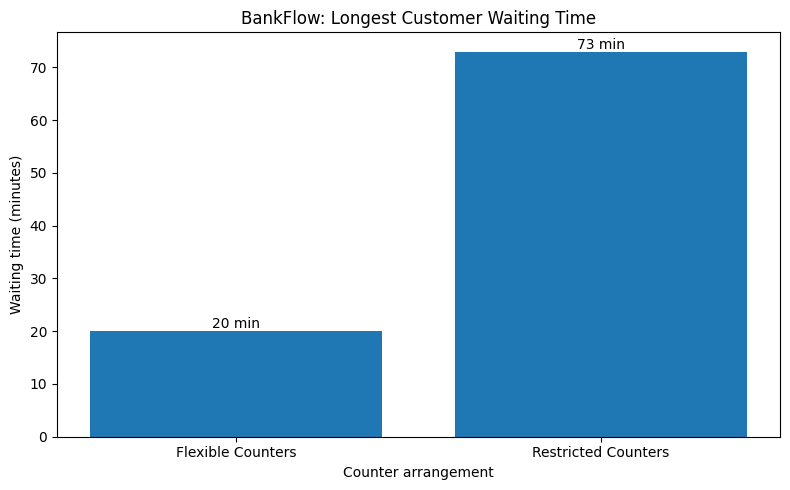

In [16]:

import matplotlib.pyplot as plt

# Longest waiting time in each scenario
scenarios = ["Flexible Counters", "Restricted Counters"]
longest_waits = [
    max(flexible_waits),
    max(restricted_waits)
]

# Create the chart
plt.figure(figsize=(8, 5))
bars = plt.bar(scenarios, longest_waits)

# Add the values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.0f} min",
        ha="center",
        va="bottom"
    )

plt.title("BankFlow: Longest Customer Waiting Time")
plt.ylabel("Waiting time (minutes)")
plt.xlabel("Counter arrangement")
plt.tight_layout()
plt.show()


In [17]:

# BANKFLOW — STEP 25
# Compare the complete customer waiting experience

import pandas as pd

comparison = pd.DataFrame({
    "Measure": [
        "Average waiting time (min)",
        "Median waiting time (min)",
        "Longest waiting time (min)",
        "Customers who waited",
        "Percentage who waited (%)"
    ],
    "Flexible Counters": [
        sum(flexible_waits) / len(flexible_waits),
        pd.Series(flexible_waits).median(),
        max(flexible_waits),
        sum(wait > 0 for wait in flexible_waits),
        sum(wait > 0 for wait in flexible_waits)
        / len(flexible_waits) * 100
    ],
    "Restricted Counters": [
        sum(restricted_waits) / len(restricted_waits),
        pd.Series(restricted_waits).median(),
        max(restricted_waits),
        sum(wait > 0 for wait in restricted_waits),
        sum(wait > 0 for wait in restricted_waits)
        / len(restricted_waits) * 100
    ]
})

print("BANKFLOW — CUSTOMER EXPERIENCE REPORT")
print("=" * 55)
print(comparison.round(2).to_string(index=False))


BANKFLOW — CUSTOMER EXPERIENCE REPORT
                   Measure  Flexible Counters  Restricted Counters
Average waiting time (min)               3.85                17.55
 Median waiting time (min)               0.00                12.50
Longest waiting time (min)              20.00                73.00
      Customers who waited              47.00                89.00
 Percentage who waited (%)              47.00                89.00


In [19]:

# BANKFLOW — STEP 25
# Analyse customer waiting times

import pandas as pd

print("FLEXIBLE COUNTERS")
print("-----------------")
print("Average wait:",
      round(sum(flexible_waits) / len(flexible_waits), 2),
      "minutes")
print("Median wait:",
      pd.Series(flexible_waits).median(),
      "minutes")
print("Longest wait:",
      max(flexible_waits),
      "minutes")
print("Customers who waited:",
      sum(wait > 0 for wait in flexible_waits),
      "out of", len(flexible_waits))

print("\nRESTRICTED COUNTERS")
print("-------------------")
print("Average wait:",
      round(sum(restricted_waits) / len(restricted_waits), 2),
      "minutes")
print("Median wait:",
      pd.Series(restricted_waits).median(),
      "minutes")
print("Longest wait:",
      max(restricted_waits),
      "minutes")
print("Customers who waited:",
      sum(wait > 0 for wait in restricted_waits),
      "out of", len(restricted_waits))


FLEXIBLE COUNTERS
-----------------
Average wait: 3.85 minutes
Median wait: 0.0 minutes
Longest wait: 20 minutes
Customers who waited: 47 out of 100

RESTRICTED COUNTERS
-------------------
Average wait: 17.55 minutes
Median wait: 12.5 minutes
Longest wait: 73 minutes
Customers who waited: 89 out of 100


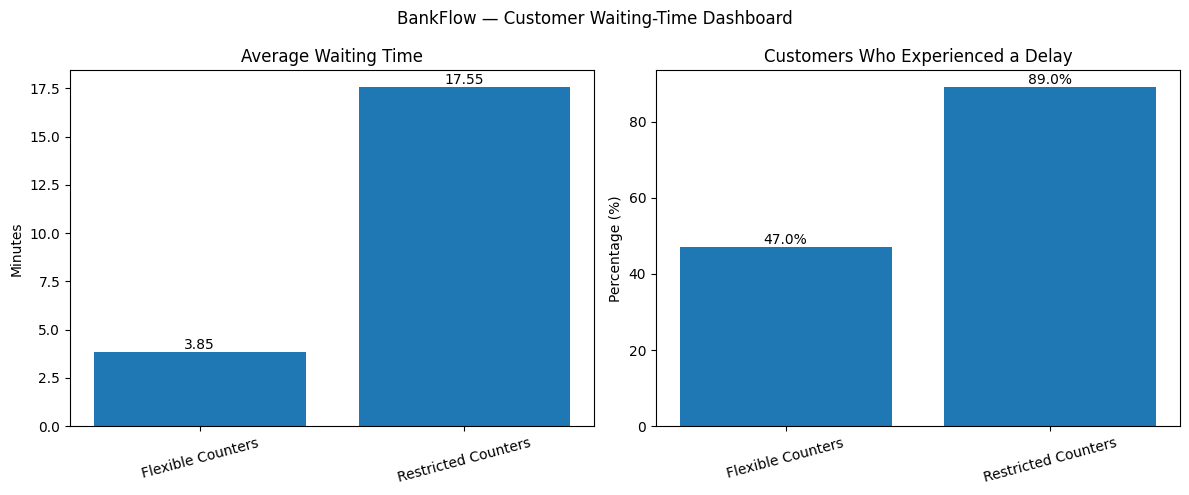

In [20]:

# BANKFLOW — STEP 26
# Compare customer experience visually

import matplotlib.pyplot as plt

scenarios = ["Flexible Counters", "Restricted Counters"]

average_waits = [
    sum(flexible_waits) / len(flexible_waits),
    sum(restricted_waits) / len(restricted_waits)
]

delay_percentages = [
    sum(wait > 0 for wait in flexible_waits)
    / len(flexible_waits) * 100,

    sum(wait > 0 for wait in restricted_waits)
    / len(restricted_waits) * 100
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Average waiting time
bars1 = axes[0].bar(scenarios, average_waits)
axes[0].set_title("Average Waiting Time")
axes[0].set_ylabel("Minutes")
axes[0].tick_params(axis="x", rotation=15)

for bar in bars1:
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )

# Chart 2: Percentage of customers who waited
bars2 = axes[1].bar(scenarios, delay_percentages)
axes[1].set_title("Customers Who Experienced a Delay")
axes[1].set_ylabel("Percentage (%)")
axes[1].tick_params(axis="x", rotation=15)

for bar in bars2:
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

plt.suptitle("BankFlow — Customer Waiting-Time Dashboard")
plt.tight_layout()
plt.show()


In [21]:

# BANKFLOW — STEP 27
# Export the project results to Excel

import pandas as pd
from google.colab import files

# Prepare results for each scenario
flexible_results_df = df.sort_values("arrival_time_min").copy()
flexible_results_df["waiting_time_min"] = flexible_waits
flexible_results_df["scenario"] = "Flexible Counters"

restricted_results_df = df.sort_values("arrival_time_min").copy()
restricted_results_df["waiting_time_min"] = restricted_waits
restricted_results_df["scenario"] = "Restricted Counters"

# Create a comparison summary
comparison_df = pd.DataFrame({
    "Measure": [
        "Average waiting time (minutes)",
        "Median waiting time (minutes)",
        "Longest waiting time (minutes)",
        "Customers who waited",
        "Customers who waited (%)"
    ],
    "Flexible Counters": [
        sum(flexible_waits) / len(flexible_waits),
        pd.Series(flexible_waits).median(),
        max(flexible_waits),
        sum(w > 0 for w in flexible_waits),
        sum(w > 0 for w in flexible_waits) / len(flexible_waits) * 100
    ],
    "Restricted Counters": [
        sum(restricted_waits) / len(restricted_waits),
        pd.Series(restricted_waits).median(),
        max(restricted_waits),
        sum(w > 0 for w in restricted_waits),
        sum(w > 0 for w in restricted_waits) / len(restricted_waits) * 100
    ]
})

# Save all four sheets into one Excel file
with pd.ExcelWriter("BankFlow_Results.xlsx") as writer:
    df.to_excel(writer, sheet_name="Original Dataset", index=False)
    flexible_results_df.to_excel(
        writer, sheet_name="Flexible Scenario", index=False
    )
    restricted_results_df.to_excel(
        writer, sheet_name="Restricted Scenario", index=False
    )
    comparison_df.round(2).to_excel(
        writer, sheet_name="Comparison Summary", index=False
    )

print("BankFlow Excel report created successfully!")

# Download the Excel workbook
files.download("BankFlow_Results.xlsx")


BankFlow Excel report created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>